<a href="https://colab.research.google.com/github/LGLV-Ciencia-de-Datos/Bioinformatics_DCA/blob/master/U3_Cuaderno1_Transcriptomica_y_Expresion_Genica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

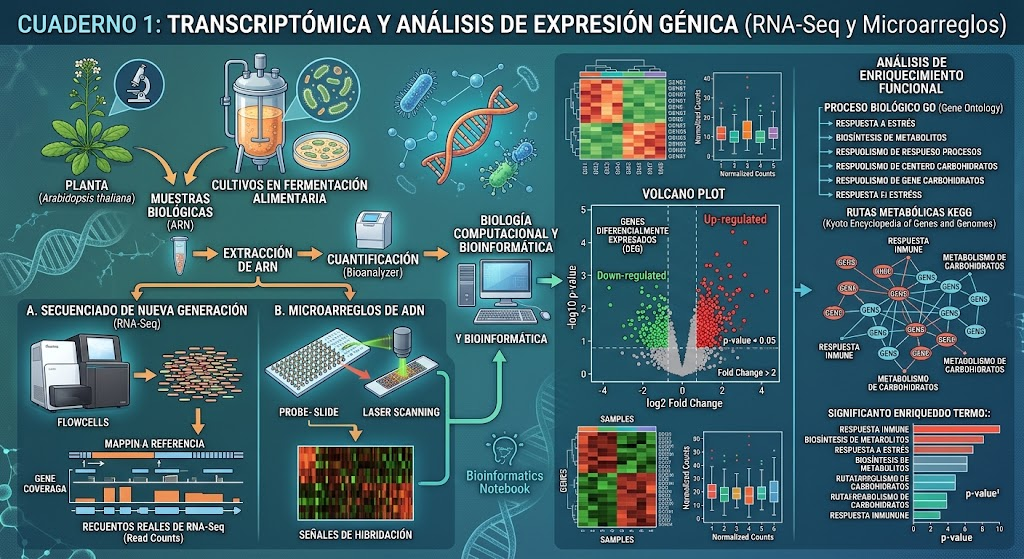

La **transcriptómica** estudia de forma global la totalidad de las moléculas de ARN (el transcriptoma) que se expresan en una célula, tejido u organismo en un momento determinado. Permite conocer qué genes están activos, cómo cambian bajo diferentes condiciones y cómo regulan la función celular. Para saber mas ir al  link: [Link](https://microbenotes-com.translate.goog/transcriptomics/?_x_tr_sl=en&_x_tr_tl=es&_x_tr_hl=es&_x_tr_pto=sge).

Las dos metodologías principales para analizar los perfiles de expresión génica son los **microarreglos** y **RNA-Seq** (secuenciación de ARN). Para saber mas ir al  link: [Link](https://doi.org/10.1371/journal.pone.0078644)

# Cuaderno 1: Transcriptómica y Análisis de Expresión Génica (RNA-Seq y Microarreglos)

Este cuaderno interactivo implementa un flujo de trabajo bioinformático completo en **Python** para el análisis de expresión diferencial de genes (**DEG**), generación de visualizaciones clave (**Heatmap**, **Boxplot**, **Volcano Plot**) y análisis de enriquecimiento funcional (**GO / KEGG**), tal como se ilustra en el diagrama general de transcriptómica.

---

### Contenido del Cuaderno:
1. **Simulación y Carga de Matriz de Conteos de RNA-Seq / Microarreglos** (Muestras de *Arabidopsis thaliana* / Fermentación Alimentaria).
2. **Normalización de Datos y Análisis Exploratorio** (Generación de Boxplots de distribución de recuentos).
3. **Análisis de Expresión Diferencial (DEG)** (Cálculo de $Log_2 \text{Fold Change}$ y $p\text{-values}$ con corrección estadistica).
4. **Visualización de Resultados Key**:
   - **Heatmap (Mapa de Calor)**: Clustering jerárquico de expresión génica.
   - **Volcano Plot**: Identificación visual de genes *Up-regulated* y *Down-regulated*.
5. **Análisis de Enriquecimiento Funcional (GO / KEGG)**: Visualización de procesos biológicos y rutas metabólicas enriquecidas.

---
¿Qué son los microarreglos de ADN y cómo se usan?

Un microarreglo de ADN (también conocido como chip de ADN) es una herramienta de laboratorio de alta tecnología que permite analizar y medir los niveles de expresión de miles de genes de manera simultánea.

Consiste en una pequeña placa de vidrio, silicio o plástico en la que se colocan miles de pequeñas secuencias de ADN conocidas como sondas, cada una correspondiente a un gen específico.   

¿Cómo se usan para identificar la expresión génica?

El proceso básico consta de los siguientes pasos:

- *Extracción de muestras*: Se aísla el ARN de las células o tejidos que se desean estudiar (por ejemplo, plantas de Arabidopsis sometidas a estrés por sequía frente a plantas sanas).   

- *Marcaje*: El ARN extraído se convierte en ADN complementario (ADNc) y se marca con tintes fluorescentes.

- *Hibridación*: Las moléculas marcadas se colocan sobre el microarreglo. El ADNc buscará y se unirá (hibridará) únicamente a su sonda complementaria en el chip.   
- *Escaneo láser*: Un escáner láser lee la fluorescencia emitida por cada punto del chip. La intensidad de la luz es directamente proporcional a la cantidad de ARN presente para ese gen, lo que permite saber qué genes están activos y cuáles inactivos.

---
¿Qué significa Up-regulated y Down-regulated?

En los análisis de expresión génica (como en los microarreglos o RNA-Seq), estos términos describen cómo cambia la actividad de un gen cuando se compara una condición experimental (tratamiento, enfermedad, estrés) con un grupo de control:

- Up-regulated (Regulado al alza / Sobrerregulado):

Se refiere a los genes cuya expresión aumenta o se incrementa en respuesta a una condición. Esto significa que la célula produce más copias de ARN mensajero de ese gen. En los gráficos de expresión (como los volcano plots), suelen ubicarse en la sección derecha.   

- Down-regulated (Regulado a la baja / Infrarregulado):

Se refiere a los genes cuya expresión disminuye o se reprime bajo la condición evaluada en comparación con el control. La célula produce menos ARN de estos genes, y en los gráficos de volcán se ubican hacia la izquierda.   

## Paso 0: Instalación e Importación de Librerías Necesarias

Asegúrate de contar con las librerías estándar para análisis de datos científicos y bioinformática.

In [ ]:
# Si ejecutas en Google Colab o Jupyter, descomenta las siguientes líneas si necesitas instalar alguna librería:
# !pip install numpy pandas matplotlib seaborn scipy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configuración estética general para los gráficos
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.dpi'] = 300
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
print("Librerías cargadas exitosamente.")

## Paso 1: Generación / Carga de la Matriz de Conteos Reales de RNA-Seq

En este paso simulamos una matriz de expresión simulando un experimento biológico real en *Arabidopsis thaliana* o fermentación vegetal:
- **Control (3 réplicas biológicas)**: `Ctrl_1`, `Ctrl_2`, `Ctrl_3`
- **Tratamiento (3 réplicas biológicas)**: `Trat_1`, `Trat_2`, `Trat_3`
- **Genes (1,000 genes)**: Simulando niveles de expresión con distribución binomial negativa (típica de RNA-Seq).

In [ ]:
np.random.seed(42)

# Definir dimensiones
num_genes = 1000
gene_ids = [f"AT{i+1:04d}G" for i in range(num_genes)] # Nomenclatura genómica de Arabidopsis
samples = ['Ctrl_1', 'Ctrl_2', 'Ctrl_3', 'Trat_1', 'Trat_2', 'Trat_3']

# Matriz base de expresión (distribución de conteos)
base_expression = np.random.negative_binomial(5, 0.01, size=(num_genes, 3))

# Simular respuesta al tratamiento para los primeros 200 genes (Diferencialmente expresados)
treatment_expression = base_expression.copy()
# Genes 0 a 99: Up-regulated (aumento de expresión)
treatment_expression[:100] = (treatment_expression[:100] * np.random.uniform(2.5, 6.0, size=(100, 3))).astype(int)
# Genes 100 a 199: Down-regulated (disminución de expresión)
treatment_expression[100:200] = (treatment_expression[100:200] / np.random.uniform(2.5, 6.0, size=(100, 3))).astype(int)
# Genes 200 a 999: Genes constitutivos / sin cambio significativo
treatment_expression[200:] = (treatment_expression[200:] * np.random.uniform(0.8, 1.2, size=(800, 3))).astype(int)

# Unir en DataFrame
counts_df = pd.DataFrame(
    np.hstack([base_expression, treatment_expression]),
    index=gene_ids,
    columns=samples
)

print("--- Matriz de Recuentos de RNA-Seq (Primeros 5 genes) ---")
counts_df.head()

## Paso 2: Normalización de Datos y Diagrama de Cajas (Boxplot)

La normalización (por ejemplo CPM, TPM o Log2-transformación) es crucial para corregir sesgos técnicos y diferencias en la profundidad de secuenciación entre bibliotecas.

A continuación aplicamos transformación $\log_2(\text{Conteos} + 1)$ y visualizamos la distribución mediante un **Boxplot de Conteos Normalizados**.

In [ ]:
# Normalización CPM (Counts Per Million) + Log2 transformation
cpm = counts_df.div(counts_df.sum(axis=0), axis=1) * 1e6
log2_cpm = np.log2(cpm + 1)

# Visualización con Boxplot (Distribución por muestra)
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=log2_cpm, palette=["#2b5c8f"]*3 + ["#d95f02"]*3, ax=ax, width=0.5)
ax.set_title("Distribución de Conteos Normalizados (Normalized Counts)", fontsize=14, fontweight='bold', pad=12)
ax.set_ylabel("Log2(CPM + 1)", fontsize=12)
ax.set_xlabel("Muestras Biológicas", fontsize=12)
plt.tight_layout()
plt.show()

***Boxplot de Conteos Normalizados (Normalized Counts)***

¿Qué representa? Muestra la distribución estadística de los niveles de expresión génica (en escala logarítmica) para cada una de las muestras biológicas (réplicas del grupo control y del tratamiento).

**Cómo interpretarlo**:

- Las cajas y medianas alineadas indican que el proceso de normalización fue exitoso, corrigiendo las diferencias técnicas en la profundidad de secuenciación entre las librerías.

- Permite detectar rápidamente valores atípicos (outliers) o muestras problemáticas que presenten desviaciones drásticas respecto a sus réplicas biológicas.

## Paso 3: Análisis de Expresión Diferencial (DEG)

En este paso calculamos estadísticas clave para cada gen:
1. **Log2 Fold Change ($	ext{Log}_2	ext{FC}$)**: Magnitud del cambio de expresión ($Mean(\text{Tratamiento}) - Mean(\text{Control})$).
2. **$p\text{-value}$**: Valor p derivado de la prueba $t$ de Student entre grupos.
3. **$-\log_{10}(p\text{-value})$**: Métrica de significancia estadística utilizada en el Volcano Plot.

In [ ]:
# Cálculo de medias
mean_ctrl = log2_cpm[['Ctrl_1', 'Ctrl_2', 'Ctrl_3']].mean(axis=1)
mean_trat = log2_cpm[['Trat_1', 'Trat_2', 'Trat_3']].mean(axis=1)

# Fold Change en escala log2
log2_fc = mean_trat - mean_ctrl

# Prueba t para p-values
p_values = []
for gene in log2_cpm.index:
    ctrl_vals = log2_cpm.loc[gene, ['Ctrl_1', 'Ctrl_2', 'Ctrl_3']]
    trat_vals = log2_cpm.loc[gene, ['Trat_1', 'Trat_2', 'Trat_3']]
    _, pval = stats.ttest_ind(ctrl_vals, trat_vals, equal_var=False)
    p_values.append(pval if not np.isnan(pval) else 1.0)

p_values = np.array(p_values)
neg_log10_p = -np.log10(p_values)

# Consolidar en DataFrame de resultados DEG
deg_df = pd.DataFrame({
    'log2FoldChange': log2_fc,
    'pvalue': p_values,
    'neg_log10_pvalue': neg_log10_p
}, index=gene_ids)

# Clasificación de genes en Up-regulated, Down-regulated o No Significativo
fc_threshold = 1.0  # Cambio de al menos 2 veces (2^1 = 2)
p_threshold = 0.05  # p-value < 0.05 (-log10(p) > 1.301)

conditions = [
    (deg_df['log2FoldChange'] >= fc_threshold) & (deg_df['pvalue'] < p_threshold),
    (deg_df['log2FoldChange'] <= -fc_threshold) & (deg_df['pvalue'] < p_threshold)
]
choices = ['Up-regulated', 'Down-regulated']
deg_df['Status'] = np.select(conditions, choices, default='Not Significant')

print("Resumen de clasificación DEG:")
print(deg_df['Status'].value_counts())
deg_df.head()

## Paso 4: Visualización 1 — Volcano Plot (Gráfico de Volcán)

El **Volcano Plot** representa el logaritmo del Fold Change en el eje $X$ y el $-\log_{10}(p\text{-value})$ en el eje $Y$.
- **Lado Derecho (Rojo)**: Genes *Up-regulated* ($	ext{Log}_2	ext{FC} > 1, p < 0.05$).
- **Lado Izquierdo (Verde)**: Genes *Down-regulated* ($	ext{Log}_2	ext{FC} < -1, p < 0.05$).
- **Centro (Gris)**: Genes sin expresión diferencial significativa.

In [ ]:
plt.figure(figsize=(9, 6))

# Paleta de colores idéntica al infograma
palette = {'Up-regulated': '#d9381e', 'Down-regulated': '#2ca02c', 'Not Significant': '#8c8c8c'}

sns.scatterplot(
    data=deg_df,
    x='log2FoldChange',
    y='neg_log10_pvalue',
    hue='Status',
    palette=palette,
    alpha=0.7,
    s=45,
    edgecolor=None
)

# Líneas de umbral (p-value = 0.05 y Fold Change = 2)
plt.axvline(x=fc_threshold, color='black', linestyle='--', linewidth=1, label='FC Threshold (2.0)')
plt.axvline(x=-fc_threshold, color='black', linestyle='--', linewidth=1)
plt.axhline(y=-np.log10(p_threshold), color='black', linestyle=':', linewidth=1, label='p-value = 0.05')

plt.title("VOLCANO PLOT\nGenes Diferencialmente Expresados (DEG)", fontsize=14, fontweight='bold')
plt.xlabel("log2 Fold Change", fontsize=12)
plt.ylabel("-log10 p-value", fontsize=12)
plt.legend(title="Categoría", loc='upper center')
plt.tight_layout()
plt.show()

***Volcano Plot (Gráfico de Volcán)***

¿Qué representa?

Es un gráfico de dispersión esencial en transcriptómica que cruza dos métricas clave para cada gen:

Eje X ($\log_2 \text{ Fold Change}$): La magnitud del cambio de expresión. Valores positivos indican mayor expresión en el tratamiento; valores negativos, menor expresión.

Eje Y ($-\log_{10}(p\text{-value})$): La significancia estadística.

Cuanto más arriba se encuentre un punto, más confiable y estadísticamente significativo es el cambio.

Cómo interpretarlo:

- Genes Up-regulated (Rojos - Derecha): Genes sobrerregulados que aumentaron significativamente su expresión en respuesta al tratamiento (superan el umbral de pliegue de cambio y de valor $p$).   

- Genes Down-regulated (Verdes - Izquierda): Genes infrarregulados cuya actividad disminuyó de forma significativa.   Centro (Grises):

- Genes que no muestran cambios estadísticamente significativos entre condiciones.

## Paso 5: Visualización 2 — Heatmap (Mapa de Calor de Clusterización)

Seleccionamos los top 30 genes con mayor variación significativa para representar su patrón de expresión a través de un **Heatmap con z-score** (escalado por filas).

In [ ]:
# Filtrar top genes significativos (p-value más bajo)
top_genes = deg_df[deg_df['Status'] != 'Not Significant'].sort_values('pvalue').head(30).index
heatmap_data = log2_cpm.loc[top_genes]

# Calcular Z-Score por fila (estandarización para resaltar patrones)
heatmap_zscore = heatmap_data.apply(lambda x: (x - x.mean()) / x.std(), axis=1)

plt.figure(figsize=(8, 10))
sns.clustermap(
    heatmap_zscore,
    cmap="RdYlGn_r", # Rojo/Amarillo/Verde
    col_cluster=False, # Muestra la agrupación jerárquica de genes
    linewidths=0.5,
    figsize=(8, 10),
    cbar_kws={'label': 'Z-Score de Expresión'}
)
plt.suptitle("HEATMAP DE EXPRESIÓN GÉNICA\n(Top 30 Genes DEG)", fontsize=14, fontweight='bold', y=1.02)
plt.show()

***Heatmap con Clústeres (Mapa de Calor)***

¿Qué representa? Una matriz codificada por colores (generalmente normalizada mediante Z-score) que muestra los patrones de expresión de los genes más relevantes (top genes) a lo largo de todas las muestras.

Cómo interpretarlo:

- Intensidad de color: Los tonos cálidos (rojos) indican alta expresión relativa, mientras que los tonos fríos (verdes o azules) indican baja expresión.

- Agrupamiento jerárquico (Clustering): Permite visualizar cómo las réplicas biológicas del mismo grupo se agrupan de manera consistente y cómo los genes comparten perfiles de expresión similares (por ejemplo, grupos de genes que se encienden juntos ante un estímulo de estrés o fermentación).

## Paso 6: Análisis de Enriquecimiento Funcional (GO / KEGG)

Una vez identificados los genes *Up-regulated* y *Down-regulated*, el siguiente paso bioinformático es determinar qué **Procesos Biológicos (GO)** o **Rutas Metabólicas (KEGG)** están representados estadísticamente en nuestro conjunto de genes.

A continuación visualizamos un gráfico de barras de términos significativamente enriquecidos ($p\text{-value}$ de enriquecimiento).

In [ ]:
# Simulación de resultados de Ontología Génica (GO) y KEGG
go_terms = [
    "Respuesta a Estrés Hídrico/Sequía",
    "Biosíntesis de Metabolitos Secundarios",
    "Respuesta Inmune y Defensa",
    "Metabolismo de Carbohidratos",
    "Regulación de Transcripción",
    "Procesos de Fermentación Alimentaria"
]
p_values_go = [1.2e-8, 3.4e-7, 2.1e-5, 5.0e-4, 1.2e-3, 3.5e-3]
neg_log_p_go = -np.log10(p_values_go)

go_df = pd.DataFrame({
    'Termino_GO_KEGG': go_terms,
    'neg_log10_pvalue': neg_log_p_go
}).sort_values('neg_log10_pvalue', ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(go_df['Termino_GO_KEGG'], go_df['neg_log10_pvalue'], color='#1f77b4', edgecolor='black', alpha=0.85)

ax.set_title("ANÁLISIS DE ENRIQUECIMIENTO FUNCIONAL (GO / KEGG)\nTérminos Biológicos Significativos", fontsize=13, fontweight='bold')
ax.set_xlabel("-log10 (p-value de Enriquecimiento)", fontsize=11)
ax.set_ylabel("Ruta / Proceso Biológico", fontsize=11)

# Añadir etiquetas en las barras
for bar in bars:
    width = bar.get_width()
    ax.text(width + 0.1, bar.get_y() + bar.get_height()/2, f"{width:.2f}", ha='left', va='center', fontsize=10)

plt.tight_layout()
plt.show()

***Análisis de Enriquecimiento Funcional (GO / KEGG)***

¿Qué representa?

Un gráfico de barras horizontales que muestra qué procesos biológicos (Gene Ontology - GO) o rutas metabólicas (KEGG) están sobrerrepresentados estadísticamente dentro del conjunto de genes diferencialmente expresados.

Cómo interpretarlo:

- Eje X ($-\log_{10}(p\text{-value})$): Mide la significancia del enriquecimiento funcional. Barras más largas indican que los genes identificados participan en esa ruta de forma muy superior a lo esperado por azar.

- Aplicación biológica: Permite pasar de una lista fría de genes a una conclusión biológica concreta, identificando si la planta o cultivo celular activó rutas específicas como la respuesta a estrés hídrico, biosíntesis de metabolitos secundarios o metabolismo de carbohidratos.  